# Logistic Regression with Python - Case Study

For this case study we will work with the [Titanic Data Set from Kaggle](https://www.kaggle.com/c/titanic). This is a very famous dataset and very often adopted for students' first step in machine learning! 

We'll be trying to predict a classification - survival or deceased - by implementing Logistic Regression in Python.

We'll use a "semi-cleaned" version of the titanic dataset; if you use the data set directly hosted on Kaggle, you may need to perform some additional data cleaning operations not shown in this lecture notebook.

## Import  Data Analysis and Visualization Libraries

In [35]:
%pip install numpy pandas matplotlib seaborn openpyxl
%pip install ipywidgets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Import Dataset

In [36]:
data = pd.read_csv('titanic.csv', index_col="PassengerID")
data.head()

,Survived,Pass. Class,Name,Age,Nr Siblings/Spouses,Nr Parents/Children,Ticket,Fare,Cabin,Sex,Embarked - Queenstown,Embarked - Southampton
PassengerID,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,1,0,1
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,0,0,0
3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,0,1
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,0,0,1
5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,1,0,1


![alt text](titanic_route.png "Title")

In [37]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Survived                891 non-null    int64  
 1   Pass. Class             891 non-null    int64  
 2   Name                    891 non-null    str    
 3   Age                     714 non-null    float64
 4   Nr Siblings/Spouses     891 non-null    int64  
 5   Nr Parents/Children     891 non-null    int64  
 6   Ticket                  891 non-null    str    
 7   Fare                    891 non-null    float64
 8   Cabin                   204 non-null    str    
 9   Sex                     891 non-null    int64  
 10  Embarked - Queenstown   891 non-null    int64  
 11  Embarked - Southampton  891 non-null    int64  
dtypes: float64(2), int64(7), str(3)
memory usage: 83.7 KB


# Exploratory Data Analysis

### TO DO: Visualize data. Which passenger class has most survivors

## Missing Data

We can use seaborn to create a simple heatmap to see where are missing data.

<Axes: ylabel='PassengerID'>

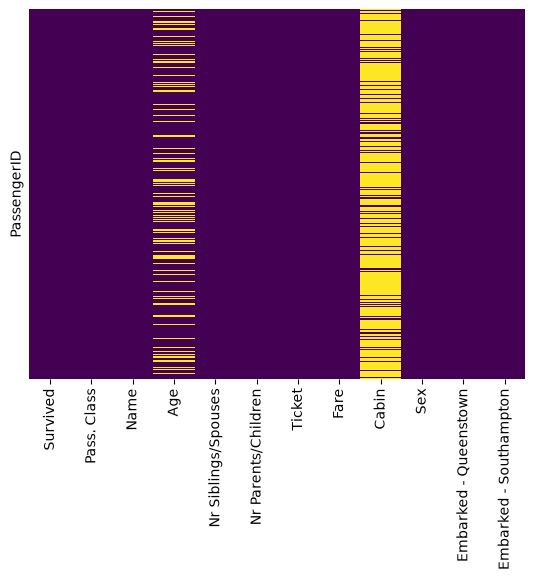

In [38]:
sns.heatmap(data.isnull(), yticklabels=False, cbar=False, cmap='viridis')

<Axes: xlabel='Survived', ylabel='count'>

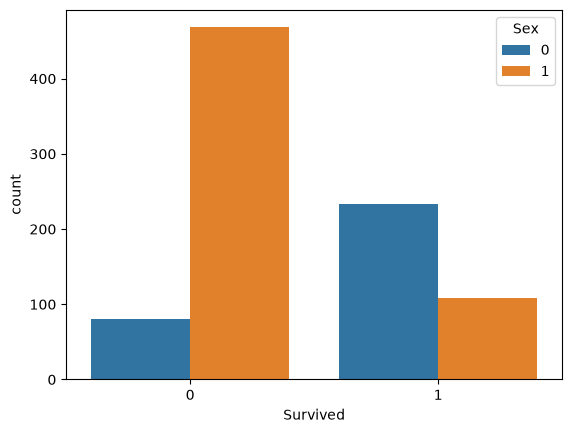

In [39]:
sns.countplot(x='Survived', hue='Sex', data=data)

<Axes: xlabel='Survived', ylabel='count'>

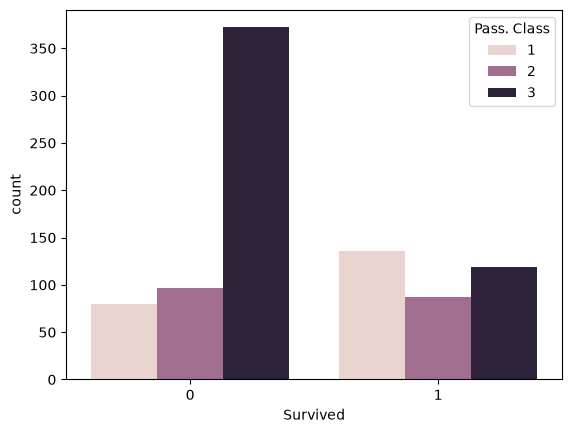

In [40]:
sns.countplot(x='Survived', hue='Pass. Class', data=data)

## Missing Data
If data is missing, we cannot use the entire dataset for training. We have to choose:
1. Fill the missing data artificially
2. Discard the missing data

### TO DO: Visualize the missing data and prepare the dataset for training
Hint: Generate artificial values when the missing data can be estimated and when it is not frequent

<Axes: xlabel='Pass. Class', ylabel='Age'>

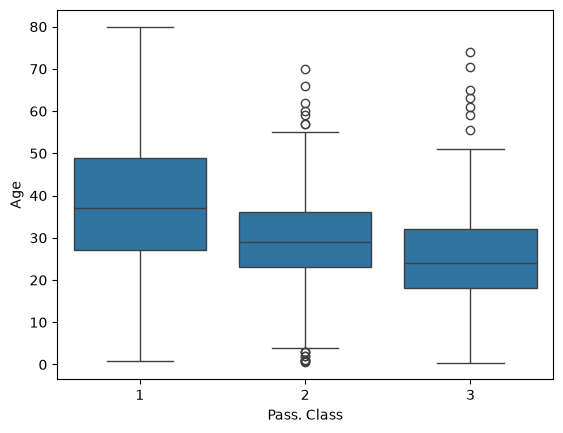

In [41]:
sns.boxplot(x='Pass. Class', y='Age', data=data) 
# how does age change with the Class (because old people have more money)

In [42]:
print(data.groupby('Pass. Class')['Age'].median())

Pass. Class
1    37.0
2    29.0
3    24.0
Name: Age, dtype: float64


In [43]:
def impute_age(cols):
    Age = cols['Age']
    Pclass = cols['Pass. Class'] # 注意：请确认你的列名就是 'Pass. Class'（中间有空格和点）
    if pd.isnull(Age):
        if Pclass == 1:
            return 37
        elif Pclass == 2:
            return 29
        else:
            return 24
    else:
        return Age

<Axes: ylabel='PassengerID'>

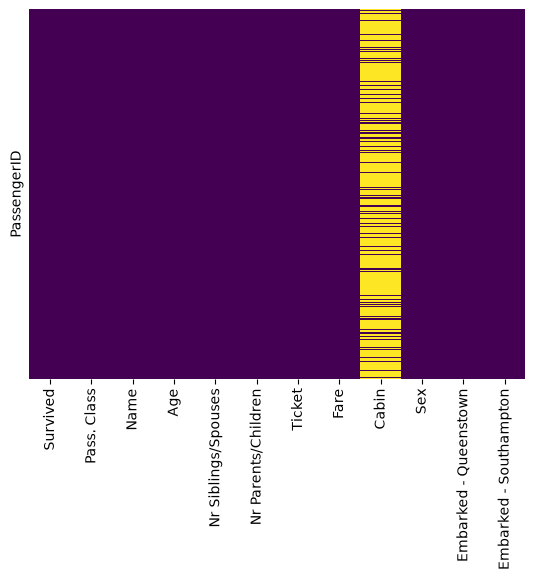

In [44]:
data['Age'] = data[['Age', 'Pass. Class']].apply(impute_age, axis=1)
sns.heatmap(data.isnull(), yticklabels=False, cbar=False, cmap='viridis')

## Managing Cabin column

In [45]:
data.drop(['Cabin', 'Name', 'Ticket'], axis=1, inplace=True)

/tmp/ipykernel_20065/434600364.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(['Cabin', 'Name', 'Ticket'], axis=1, inplace=True)


In [46]:
data.head()

,Survived,Pass. Class,Age,Nr Siblings/Spouses,Nr Parents/Children,Fare,Sex,Embarked - Queenstown,Embarked - Southampton
PassengerID,,,,,,,,,
1,0,3,22.0,1,0,7.2500,1,0,1
2,1,1,38.0,1,0,71.2833,0,0,0
3,1,3,26.0,0,0,7.9250,0,0,1
4,1,1,35.0,1,0,53.1000,0,0,1
5,0,3,35.0,0,0,8.0500,1,0,1


# Building a Logistic Regression model

Let's start by splitting our data into a training set and test set as we did in the linear regression case study.

In [47]:
from sklearn.model_selection import train_test_split
X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

### TO DO: Train a logistic regression model and use it on the test set

In [48]:
from sklearn.linear_model import LogisticRegression
logmodel = LogisticRegression()
logmodel.fit(X_train, y_train)

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

## Performance Evaluation

Confusion Matrix:

\begin{array}{ccc}
& \text{Observed values} &\\
\text{Predicted values} &
\begin{bmatrix}
    TN & FP \\
    FN & TP \\
\end{bmatrix} &
\end{array}


 
<br>

- **TP (True Positive):** Model predicts *positive* and it’s actually *positive*  
- **FP (False Positive):** Model predicts *positive* but it’s actually *negative*  (*false alarm*)  
- **TN (True Negative):** Model predicts *negative* and it’s actually *negative*   
- **FN (False Negative):** Model predicts *negative* but it’s actually *positive*  (*missed detection*) 

F1-score (harmonic mean of precision and recall):
$$
F1 = \frac{2 \times precision \times recall}{precision + recall}
$$
where:
- precision: $\frac{TP}{TP+FP}$ ratio of true positive (real survivors) over all predicted positive (all predicted as survivors, even if some are not) Precision measures the proportion of positive predictions that were actually correct
- recall: $\frac{TP}{TP+FN}$ ratio of true positive (real survivors) over all that should have been predicted as survivors (all predicted as survivors, even if some are not) Recall measures the proportion of actual positives that were correctly identified.

### TO DO: Evaluate the performance of the model

In [49]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
predictions = logmodel.predict(X_test)
predictions[:10]

array([0, 1, 1, 0, 0, 0, 0, 0, 1, 1])

[[133  21]
 [ 38  76]]


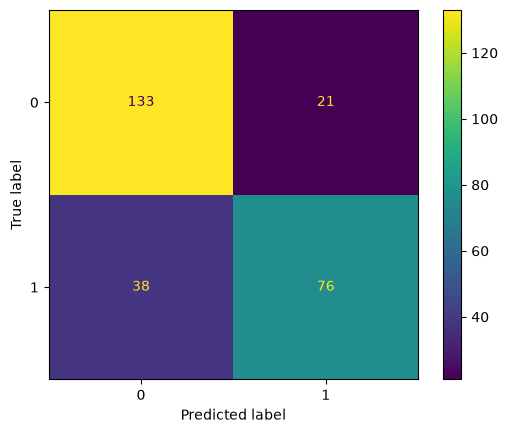

In [50]:
conf_mat = confusion_matrix(y_test, predictions)
print(conf_mat)

matrix = ConfusionMatrixDisplay(conf_mat).plot(values_format=".0f")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.show()

In [51]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.78      0.86      0.82       154
           1       0.78      0.67      0.72       114

    accuracy                           0.78       268
   macro avg       0.78      0.77      0.77       268
weighted avg       0.78      0.78      0.78       268



Not so bad! You might want to explore other features and the full Titanic Kaggle dataset; some suggestions for feature selection:

* Try grabbing the Title (Dr., Mr., Mrs, etc..) from the name as a feature
* Maybe Ticket information could be exploited

Notice that, when dealing with non-numeric features, it is suggested to convert them into numerical values.

## Improving the model: non-numerical features

In [52]:
# Load original dataset
data = pd.read_csv('titanic.csv', index_col="PassengerID")                               # Import dataset
data.head()

,Survived,Pass. Class,Name,Age,Nr Siblings/Spouses,Nr Parents/Children,Ticket,Fare,Cabin,Sex,Embarked - Queenstown,Embarked - Southampton
PassengerID,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,1,0,1
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,0,0,0
3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,0,1
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,0,0,1
5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,1,0,1


### From non-numerical to numerical features
Regression models use numerical features to estimate an output. Categorical data can be converted to numerical data through one-hot encoding, that is, a binary vector where the value of 1 represents the active category.

**Example**

Title = {'Mr.', 'Mrs.', 'Miss'}

$$
\begin{bmatrix}
1 \\ 0 \\ 0
\end{bmatrix} \longrightarrow \mathrm{Mr.}
\qquad \qquad
\begin{bmatrix}
0 \\ 1 \\ 0
\end{bmatrix} \longrightarrow \mathrm{Mrs.}
\qquad \qquad
\begin{bmatrix}
0 \\ 0 \\ 1
\end{bmatrix} \longrightarrow \mathrm{Miss}
$$

### TO DO: Convert the "Ticket" and "Title" information into numerical values
- Hint 1 [see below]: How to extract the Title from the name
- Hint 2 [see below]: Group together different titles to simplify the model
- Hint 3 [see below]: Tickets can be distinguished based on the first letter of their name

In [53]:
print(data['Name'].values[0])

# We extract from 'Name' a sequence of letters (A-Za-z) of any length (+) that ends with a dot (\.)
data['Title'] = data['Name'].str.extract('([A-Za-z]+)\.')
# data.head()

Braund, Mr. Owen Harris


<>:4: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
<>:4: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
/tmp/ipykernel_20065/590210649.py:4: SyntaxWarning: "\." is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\."? A raw string is also an option.
  data['Title'] = data['Name'].str.extract('([A-Za-z]+)\.')


<StringArray>
[      'Mr',      'Mrs',     'Miss',   'Master',      'Don',      'Rev',
       'Dr',      'Mme',       'Ms',    'Major',     'Lady',      'Sir',
     'Mlle',      'Col',     'Capt', 'Countess', 'Jonkheer']
Length: 17, dtype: str


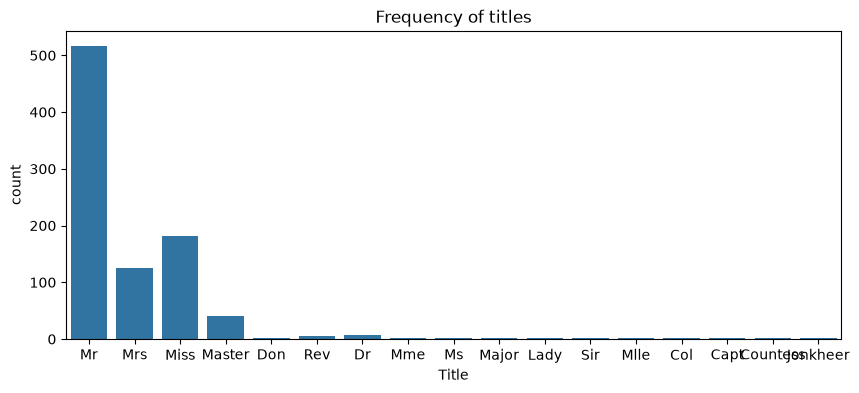

In [ ]:
print(data['Title'].unique()) 

plt.figure(figsize=(10, 4))
sns.countplot(data=data, x='Title')
plt.title('Frequency of titles')
plt.show() 
# it's not good to have many categories with few data for that category

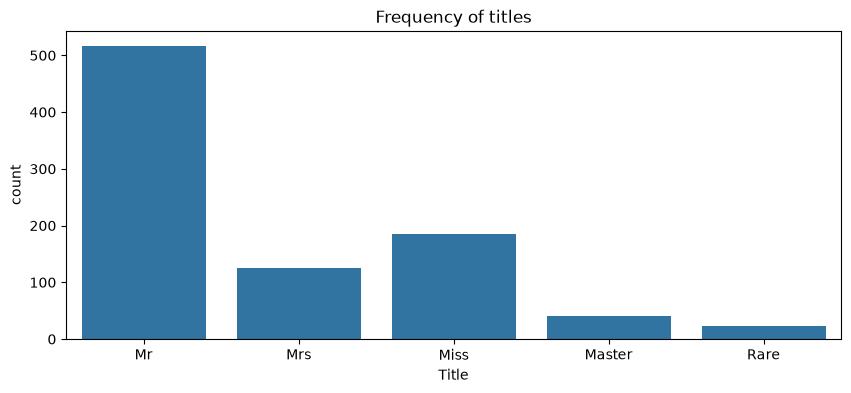

In [55]:
# We group together different classes
data['Title'] = data['Title'].replace('Mme', 'Mrs')
data['Title'] = data['Title'].replace(['Mlle', 'Ms'], 'Miss')
data['Title'] = data['Title'].replace(['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')

plt.figure(figsize=(10, 4))
sns.countplot(data=data, x='Title')
plt.title('Frequency of titles')
plt.show()

In [ ]:
# We want to extract the first letter of the Ticket (given information)
data['Ticket_prefix'] = data['Ticket'].apply(lambda x: x.split()[0] if not x.isdigit() else 'No_prefix')
data['Ticket_prefix'][:5]

# or
# def split_if_not_digit(x):
#     if not x.isdigit():
#         return x.split()[0]
#     return 'No_prefix'

# lambda x: x.split()[0] if not x.isdigit() else 'No_prefix'

PassengerID
1          A/5
2           PC
3     STON/O2.
4    No_prefix
5    No_prefix
Name: Ticket_prefix, dtype: str

In [57]:
data = pd.get_dummies(data, columns=['Ticket_prefix'], drop_first=True)
data = pd.get_dummies(data, columns=['Title'], drop_first=True)
data.head() 

,Survived,Pass. Class,Name,Age,Nr Siblings/Spouses,Nr Parents/Children,Ticket,Fare,Cabin,Sex,...,Ticket_prefix_STON/O2.,Ticket_prefix_SW/PP,Ticket_prefix_W./C.,Ticket_prefix_W.E.P.,Ticket_prefix_W/C,Ticket_prefix_WE/P,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
PassengerID,,,,,,,,,,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",22.0,1,0,A/5 21171,7.2500,NaN,1,...,False,False,False,False,False,False,False,True,False,False
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0,1,0,PC 17599,71.2833,C85,0,...,False,False,False,False,False,False,False,False,True,False
3,1,3,"Heikkinen, Miss. Laina",26.0,0,0,STON/O2. 3101282,7.9250,NaN,0,...,True,False,False,False,False,False,True,False,False,False
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0,1,0,113803,53.1000,C123,0,...,False,False,False,False,False,False,False,False,True,False
5,0,3,"Allen, Mr. William Henry",35.0,0,0,373450,8.0500,NaN,1,...,False,False,False,False,False,False,False,True,False,False


## Re-train

Drop original 'Name' and 'Ticket' columns as we've extracted relevant info and estimate age as before

In [58]:
data.drop(['Name', 'Ticket', 'Cabin'], axis=1, inplace=True)
data['Age'] = data[['Age','Pass. Class']].apply(impute_age, axis=1)

/tmp/ipykernel_20065/3771052950.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(['Name', 'Ticket', 'Cabin'], axis=1, inplace=True)


Train-test split with new features, train new model, and evaluate performance

In [59]:
# Data splitting
X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

# Train model
logmodel = LogisticRegression(max_iter=1000)
logmodel.fit(X_train, y_train)

# Predict
predictions = logmodel.predict(X_test)

# Performance
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.80      0.90      0.85       154
           1       0.84      0.70      0.77       114

    accuracy                           0.82       268
   macro avg       0.82      0.80      0.81       268
weighted avg       0.82      0.82      0.81       268



AS WE CAN SEE WE GOT AN IMPROVEMENT!!!

## Predictive Imputation
Instead of estimating the age with the median value, why don't we train a regression model?

In [60]:
# Import original dataset and keep only rows relevant for age prediction
data = pd.read_csv('titanic.csv', index_col="PassengerID")
age_df = data[['Age', 'Pass. Class', 'Nr Siblings/Spouses', 'Nr Parents/Children', 'Fare']]

### TO DO: Build a linear regression model to estimate the missing age

In [61]:
# Data splitting
age_notnull = age_df[age_df['Age'].notnull()] 
age_null = age_df[age_df['Age'].isnull()] 

In [62]:
# Data splitting
X_age_train = age_notnull.drop('Age', axis=1)
y_age_train = age_notnull['Age']

# Not really a test data
X_age_test = age_null.drop('Age', axis=1)

In [63]:
from sklearn.linear_model import LinearRegression

linreg = LinearRegression()
linreg.fit(X_age_train, y_age_train)

predicted_ages = linreg.predict(X_age_test) 
data.loc[data['Age'].isnull(), 'Age'] = predicted_ages 

Perform logistic regression training as before

In [64]:
# Remove non-numerical values
data.drop(['Name', 'Ticket', 'Cabin'], axis=1, inplace=True)

# Train-test split
X = data.drop('Survived', axis=1)
y = data['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)

# Train model
logmodel = LogisticRegression(max_iter=1000)
logmodel.fit(X_train, y_train)

# Predict and evaluate
predictions = logmodel.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.78      0.88      0.83       154
           1       0.80      0.68      0.73       114

    accuracy                           0.79       268
   macro avg       0.79      0.78      0.78       268
weighted avg       0.79      0.79      0.79       268



/tmp/ipykernel_20065/1376050733.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(['Name', 'Ticket', 'Cabin'], axis=1, inplace=True)


We got a little improvement

You can try to combine the linear regression imputation and the non-numerical features